# fvcb2009

Generated by GreenSloth from this model's validations.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from mxlpy import scan

In [2]:
import math

import numpy as np
import sympy.physics.units as su
from sympy.physics.units.quantities import Quantity

from mxlpy import Slider, SteadyStateModelBuilder

def _derived_T_K(t_leaf):
    return t_leaf + 273

def _derived_Kc(t_leaf, Kc_25, E_Kc, T_K):
    return Kc_25 * np.exp((((t_leaf) - (25)) * E_Kc * 1000) / (298 * 8.31 * T_K))

def _derived_Ko(t_leaf, Ko_25, E_Ko, T_K):
    return Ko_25 * np.exp((((t_leaf) - (25)) * E_Ko * 1000) / (298 * 8.31 * T_K))

def _derived_gamma_star(t_leaf, gamma_star_25, E_gamma_star, T_K):
    return gamma_star_25 * np.exp((((t_leaf) - (25)) * E_gamma_star * 1000) / (298 * 8.31 * T_K))

def _derived_Vcmax(t_leaf, Vcmax_25, E_Vcmax, T_K):
    return Vcmax_25 * np.exp((((t_leaf) - (25)) * E_Vcmax * 1000) / (298 * 8.31 * T_K))

def _derived_Rd(t_leaf, Rd_25, E_Rd, T_K):
    return Rd_25 * np.exp((((t_leaf) - (25)) * E_Rd * 1000) / (298 * 8.31 * T_K))

def _derived_Gamma_star(O, gamma_star):
    return 1000 * gamma_star * O

def _derived_Km(O, Kc, Ko):
    return Kc * (1 + (O) / (Ko))

def _derived_Jmax(Jmax_25, E_J, H_J, S_J, T_K):
    return (Jmax_25 * np.exp((((T_K) - (298)) * E_J * 1000) / (298 * 8.31 * T_K)) * (1 + np.exp(((S_J * 298) - (H_J * 1000)) / (8.31 * 298)))) / (1 + np.exp(((S_J * T_K) - (H_J * 1000)) / (8.31 * T_K)))

def _derived_Topt(E_J, H_J, S_J):
    return ((H_J * 1000) / (S_J + 8.31 * np.log(((H_J) / (E_J)) - (1)))) - (273)

def _derived_I2(I, abs, f):
    return (I * abs * ((1) - (f))) / (2)

def _derived_J(theta, Jmax, I2):
    return ((I2 + Jmax) - (np.pow(((I2 + Jmax) ** (2)) - (4 * theta * I2 * Jmax), 1 / 2))) / (2 * theta)

def _derived_Ac_inf(Ci, Vcmax, Rd, Gamma_star, Km):
    return ((((Ci) - (Gamma_star)) * Vcmax) / (Ci + Km)) - (Rd)

def _derived_Aj_inf(Ci, Rd, Gamma_star, J):
    return ((((Ci) - (Gamma_star)) * (J) / (4)) / (Ci + 2 * Gamma_star)) - (Rd)

def _derived_Ap(Tp, Rd):
    return (3 * Tp) - (Rd)

def _derived_A_inf(Ac_inf, Aj_inf, Ap):
    return min(Ac_inf, Aj_inf, Ap)

def _derived_Ac(Ci, gi, Vcmax, Rd, Gamma_star, Km):
    return ((gi * (Ci + Km) + (Vcmax) - (Rd)) - (np.pow(((gi * (Ci + Km) + (Vcmax) - (Rd)) ** (2)) - (4 * gi * ((Vcmax * ((Ci) - (Gamma_star))) - (Rd * (Ci + Km)))), 1 / 2))) / (2)

def _derived_Aj(Ci, gi, Rd, Gamma_star, J):
    return ((gi * (Ci + 2 * Gamma_star) + ((J) / (4)) - (Rd)) - (np.pow(((gi * (Ci + 2 * Gamma_star) + ((J) / (4)) - (Rd)) ** (2)) - (4 * gi * (((J) / (4) * ((Ci) - (Gamma_star))) - (Rd * (Ci + 2 * Gamma_star)))), 1 / 2))) / (2)

def _derived_A(Ap, Ac, Aj):
    return min(Ac, Aj, Ap)

def _derived_Cc(Ci, gi, A):
    return (Ci) - ((A) / (gi))

def _derived_A_supply(Ci, g, Ca):
    return g * ((Ca) - (Ci))

def get_model() -> SteadyStateModelBuilder:
    m = SteadyStateModelBuilder()
    m.add_parameter("Ci", 300, unit=su.bar*su.micro, display_name="Ci", tex_name="C_i", slider=Slider(min="0", max="1600", step="5"))
    m.add_parameter("O", 200, unit=su.bar*su.milli, display_name="O", tex_name="O", slider=Slider(min="0", max="500", step="5"))
    m.add_parameter("I", 1000, unit=su.mol*su.micro/(su.meter**2*su.second), display_name="I", tex_name="I", slider=Slider(min="0", max="2000", step="10"))
    m.add_parameter("t_leaf", 25, unit=Quantity("celsius", abbrev="°C"), display_name="t_leaf", tex_name="t", slider=Slider(min="0", max="50", step="0.5"))
    m.add_parameter("gi", 0.3, unit=su.mol/(su.meter**2*su.second*su.bar), display_name="gi", tex_name="g_i", slider=Slider(min="0.01", max="1", step="0.01"))
    m.add_parameter("Kc_25", 260, unit=su.bar*su.micro, display_name="Kc_25", tex_name="K_{c,25}")
    m.add_parameter("Ko_25", 179, unit=su.bar*su.milli, display_name="Ko_25", tex_name="K_{o,25}")
    m.add_parameter("gamma_star_25", 0.0001845, unit=None, display_name="gamma_star_25", tex_name="\\gamma^*_{25}")
    m.add_parameter("Vcmax_25", 80, unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Vcmax_25", tex_name="V_{c,max,25}", slider=Slider(min="5", max="200", step="0.5"))
    m.add_parameter("Rd_25", 1, unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Rd_25", tex_name="R_{d,25}", slider=Slider(min="0", max="6", step="0.05"))
    m.add_parameter("Jmax_25", 160, unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Jmax_25", tex_name="J_{max,25}", slider=Slider(min="10", max="400", step="1"))
    m.add_parameter("Tp", 100, unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Tp", tex_name="T_p", slider=Slider(min="1", max="100", step="0.5"))
    m.add_parameter("E_Kc", 59.36, unit=su.joule*su.kilo/su.mol, display_name="E_Kc", tex_name="E_{K_c}")
    m.add_parameter("E_Ko", 35.94, unit=su.joule*su.kilo/su.mol, display_name="E_Ko", tex_name="E_{K_o}")
    m.add_parameter("E_gamma_star", 24.6, unit=su.joule*su.kilo/su.mol, display_name="E_gamma_star", tex_name="E_{\\gamma^*}")
    m.add_parameter("E_Vcmax", 58.52, unit=su.joule*su.kilo/su.mol, display_name="E_Vcmax", tex_name="E_{V_{c,max}}")
    m.add_parameter("E_Rd", 66.4, unit=su.joule*su.kilo/su.mol, display_name="E_Rd", tex_name="E_{R_d}")
    m.add_parameter("E_J", 37, unit=su.joule*su.kilo/su.mol, display_name="E_J", tex_name="E_J")
    m.add_parameter("H_J", 220, unit=su.joule*su.kilo/su.mol, display_name="H_J", tex_name="H")
    m.add_parameter("S_J", 710, unit=su.joule/(su.kelvin*su.mol), display_name="S_J", tex_name="S")
    m.add_parameter("theta", 0.7, unit=None, display_name="theta", tex_name="\\theta")
    m.add_parameter("abs", 0.85, unit=None, display_name="abs", tex_name="abs")
    m.add_parameter("f", 0.15, unit=None, display_name="f", tex_name="f")
    m.add_parameter("g", 0.2, unit=su.mol/(su.meter**2*su.second*su.bar), display_name="g", tex_name="g", slider=Slider(min="0.01", max="1", step="0.01"))
    m.add_parameter("Ca", 383, unit=su.bar*su.micro, display_name="Ca", tex_name="C_a", slider=Slider(min="0", max="1600", step="5"))
    m.add_derived("T_K", _derived_T_K, args=["t_leaf"], unit=su.kelvin, display_name="T_K", tex_name="T")
    m.add_derived("Kc", _derived_Kc, args=["t_leaf", "Kc_25", "E_Kc", "T_K"], unit=su.bar*su.micro, display_name="Kc", tex_name="K_c")
    m.add_derived("Ko", _derived_Ko, args=["t_leaf", "Ko_25", "E_Ko", "T_K"], unit=su.bar*su.milli, display_name="Ko", tex_name="K_o")
    m.add_derived("gamma_star", _derived_gamma_star, args=["t_leaf", "gamma_star_25", "E_gamma_star", "T_K"], unit=None, display_name="gamma_star", tex_name="\\gamma^*")
    m.add_derived("Vcmax", _derived_Vcmax, args=["t_leaf", "Vcmax_25", "E_Vcmax", "T_K"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Vcmax", tex_name="V_{c,max}")
    m.add_derived("Rd", _derived_Rd, args=["t_leaf", "Rd_25", "E_Rd", "T_K"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Rd", tex_name="R_d")
    m.add_derived("Gamma_star", _derived_Gamma_star, args=["O", "gamma_star"], unit=su.bar*su.micro, display_name="Gamma_star", tex_name="\\Gamma^*")
    m.add_derived("Km", _derived_Km, args=["O", "Kc", "Ko"], unit=su.bar*su.micro, display_name="Km", tex_name="K_c(1 + O/K_o)")
    m.add_derived("Jmax", _derived_Jmax, args=["Jmax_25", "E_J", "H_J", "S_J", "T_K"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Jmax", tex_name="J_{max}")
    m.add_derived("Topt", _derived_Topt, args=["E_J", "H_J", "S_J"], unit=Quantity("celsius", abbrev="°C"), display_name="Topt", tex_name="T_{opt}")
    m.add_derived("I2", _derived_I2, args=["I", "abs", "f"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="I2", tex_name="I_2")
    m.add_derived("J", _derived_J, args=["theta", "Jmax", "I2"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="J", tex_name="J")
    m.add_derived("Ac_inf", _derived_Ac_inf, args=["Ci", "Vcmax", "Rd", "Gamma_star", "Km"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Ac_inf", tex_name="A_{c,\\infty}")
    m.add_derived("Aj_inf", _derived_Aj_inf, args=["Ci", "Rd", "Gamma_star", "J"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Aj_inf", tex_name="A_{j,\\infty}")
    m.add_derived("Ap", _derived_Ap, args=["Tp", "Rd"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Ap", tex_name="A_p")
    m.add_derived("A_inf", _derived_A_inf, args=["Ac_inf", "Aj_inf", "Ap"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="A_inf", tex_name="A_{\\infty}")
    m.add_derived("Ac", _derived_Ac, args=["Ci", "gi", "Vcmax", "Rd", "Gamma_star", "Km"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Ac", tex_name="A_c")
    m.add_derived("Aj", _derived_Aj, args=["Ci", "gi", "Rd", "Gamma_star", "J"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Aj", tex_name="A_j")
    m.add_derived("A", _derived_A, args=["Ap", "Ac", "Aj"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="A", tex_name="A")
    m.add_derived("Cc", _derived_Cc, args=["Ci", "gi", "A"], unit=su.bar*su.micro, display_name="Cc", tex_name="C_c")
    m.add_derived("A_supply", _derived_A_supply, args=["Ci", "g", "Ca"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="A_supply", tex_name="A_{supply}")
    return m


## Figure 9.2: A–Ci of wild-type and anti-Rubisco tobacco

In [3]:
tables = {}

# Scan wt_c
to_scan = pd.DataFrame({"Ci": np.linspace(0, 900, 361), "Vcmax_25": 90.9, "Rd_25": 3.71})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Ac_inf"]].isna().any(axis=None)
tables["wt_c"] = {
    "x": np.linspace(0, 900, 361),
    "Ac_inf": frame["Ac_inf"].to_numpy(),
}

# Scan wt_j
to_scan = pd.DataFrame({"Ci": np.linspace(0, 900, 361), "Jmax_25": 182.2, "Rd_25": 1.51})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Aj_inf"]].isna().any(axis=None)
tables["wt_j"] = {
    "x": np.linspace(0, 900, 361),
    "Aj_inf": frame["Aj_inf"].to_numpy(),
}

# Scan anti_c
to_scan = pd.DataFrame({"Ci": np.linspace(0, 900, 361), "Vcmax_25": 37.4, "Rd_25": 2.27})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Ac_inf"]].isna().any(axis=None)
tables["anti_c"] = {
    "x": np.linspace(0, 900, 361),
    "Ac_inf": frame["Ac_inf"].to_numpy(),
}

  0%|          | 0/361 [00:00<?, ?it/s]

100%|██████████| 361/361 [00:00<00:00, 3868.20it/s]

  0%|          | 0/361 [00:00<?, ?it/s]

100%|██████████| 361/361 [00:00<00:00, 3907.62it/s]

  0%|          | 0/361 [00:00<?, ?it/s]

100%|██████████| 361/361 [00:00<00:00, 3997.33it/s]

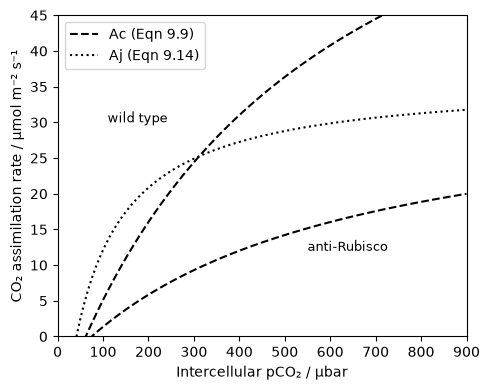

In [4]:
fig, axs = plt.subplots(nrows=1, ncols=1, figsize=(5, 4), squeeze=False)
ax0 = axs[0, 0]
ax0.text(110, 30, "wild type", fontsize=9)
ax0.text(550, 12, "anti-Rubisco", fontsize=9)
ax0.plot(tables["wt_c"]["x"], tables["wt_c"]["Ac_inf"], color="black", ls="--", label="Ac (Eqn 9.9)")
ax0.plot(tables["wt_j"]["x"], tables["wt_j"]["Aj_inf"], color="black", ls=":", label="Aj (Eqn 9.14)")
ax0.plot(tables["anti_c"]["x"], tables["anti_c"]["Ac_inf"], color="black", ls="--")
ax0.set_xlabel("Intercellular pCO₂ / µbar")
ax0.set_ylabel("CO₂ assimilation rate / µmol m⁻² s⁻¹")
ax0.set_xlim(0, 900)
ax0.set_ylim(0, 45)
ax0.legend()
plt.tight_layout()
plt.show()

## Figure 9.4: temperature dependence of electron transport

In [5]:
tables = {}

# Scan fit_low
to_scan = pd.DataFrame({"t_leaf": np.linspace(0, 7.5, 31), "Jmax_25": 50, "E_J": 44.72, "H_J": 210, "S_J": 673})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Jmax"]].isna().any(axis=None)
tables["fit_low"] = {
    "x": np.linspace(0, 7.5, 31),
    "Jmax": frame["Jmax"].to_numpy(),
}

# Scan fit
to_scan = pd.DataFrame({"t_leaf": np.linspace(7.5, 37.5, 121), "Jmax_25": 50, "E_J": 44.72, "H_J": 210, "S_J": 673})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Jmax"]].isna().any(axis=None)
tables["fit"] = {
    "x": np.linspace(7.5, 37.5, 121),
    "Jmax": frame["Jmax"].to_numpy(),
}

# Scan fit_high
to_scan = pd.DataFrame({"t_leaf": np.linspace(37.5, 50, 51), "Jmax_25": 50, "E_J": 44.72, "H_J": 210, "S_J": 673})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Jmax"]].isna().any(axis=None)
tables["fit_high"] = {
    "x": np.linspace(37.5, 50, 51),
    "Jmax": frame["Jmax"].to_numpy(),
}

# Scan fvcb
to_scan = pd.DataFrame({"t_leaf": np.linspace(0, 50, 201), "Jmax_25": 50})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Jmax"]].isna().any(axis=None)
tables["fvcb"] = {
    "x": np.linspace(0, 50, 201),
    "Jmax": frame["Jmax"].to_numpy(),
}

# Scan topt
to_scan = pd.DataFrame({"E_J": np.array([44.72,37]), "H_J": np.array([210,220]), "S_J": np.array([673,710])})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Topt"]].isna().any(axis=None)
tables["topt"] = {
    "x": np.array([1,2]),
    "Topt": frame["Topt"].to_numpy(),
}

  0%|          | 0/31 [00:00<?, ?it/s]

100%|██████████| 31/31 [00:00<00:00, 3621.72it/s]

  0%|          | 0/121 [00:00<?, ?it/s]

100%|██████████| 121/121 [00:00<00:00, 3806.51it/s]

  0%|          | 0/51 [00:00<?, ?it/s]

100%|██████████| 51/51 [00:00<00:00, 3373.91it/s]

  0%|          | 0/201 [00:00<?, ?it/s]

100%|██████████| 201/201 [00:00<00:00, 3807.41it/s]

  0%|          | 0/2 [00:00<?, ?it/s]

100%|██████████| 2/2 [00:00<00:00, 2866.92it/s]

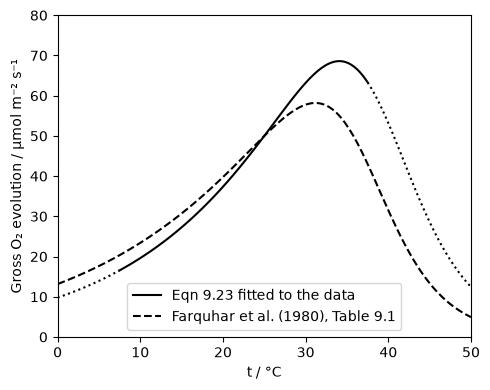

In [6]:
fig, axs = plt.subplots(nrows=1, ncols=1, figsize=(5, 4), squeeze=False)
ax0 = axs[0, 0]
ax0.plot(tables["fit"]["x"], tables["fit"]["Jmax"], color="black", ls="-", label="Eqn 9.23 fitted to the data")
ax0.plot(tables["fit_low"]["x"], tables["fit_low"]["Jmax"], color="black", ls=":")
ax0.plot(tables["fit_high"]["x"], tables["fit_high"]["Jmax"], color="black", ls=":")
ax0.plot(tables["fvcb"]["x"], tables["fvcb"]["Jmax"], color="black", ls="--", label="Farquhar et al. (1980), Table 9.1")
ax0.set_xlabel("t / °C")
ax0.set_ylabel("Gross O₂ evolution / µmol m⁻² s⁻¹")
ax0.set_xlim(0, 50)
ax0.set_ylim(0, 80)
ax0.legend()
plt.tight_layout()
plt.show()

## Figure 9.5: modelled CO₂ and light responses

In [7]:
tables = {}

# Scan ac
to_scan = pd.DataFrame({"Ci": np.linspace(0, 700, 281)})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Ac_inf"]].isna().any(axis=None)
tables["ac"] = {
    "x": np.linspace(0, 700, 281),
    "Ac_inf": frame["Ac_inf"].to_numpy(),
}

# Scan i1000
to_scan = pd.DataFrame({"Ci": np.linspace(0, 700, 281), "I": 1000})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_inf","Aj_inf"]].isna().any(axis=None)
tables["i1000"] = {
    "x": np.linspace(0, 700, 281),
    "A_inf": frame["A_inf"].to_numpy(),
    "Aj_inf": frame["Aj_inf"].to_numpy(),
}

# Scan i500
to_scan = pd.DataFrame({"Ci": np.linspace(0, 700, 281), "I": 500})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_inf","Aj_inf"]].isna().any(axis=None)
tables["i500"] = {
    "x": np.linspace(0, 700, 281),
    "A_inf": frame["A_inf"].to_numpy(),
    "Aj_inf": frame["Aj_inf"].to_numpy(),
}

# Scan i300
to_scan = pd.DataFrame({"Ci": np.linspace(0, 700, 281), "I": 300})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_inf","Aj_inf"]].isna().any(axis=None)
tables["i300"] = {
    "x": np.linspace(0, 700, 281),
    "A_inf": frame["A_inf"].to_numpy(),
    "Aj_inf": frame["Aj_inf"].to_numpy(),
}

# Scan c500
to_scan = pd.DataFrame({"I": np.linspace(0, 2000, 201), "Ci": 500})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_inf","Aj_inf"]].isna().any(axis=None)
tables["c500"] = {
    "x": np.linspace(0, 2000, 201),
    "A_inf": frame["A_inf"].to_numpy(),
    "Aj_inf": frame["Aj_inf"].to_numpy(),
}

# Scan c250
to_scan = pd.DataFrame({"I": np.linspace(0, 2000, 201), "Ci": 250})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_inf","Aj_inf"]].isna().any(axis=None)
tables["c250"] = {
    "x": np.linspace(0, 2000, 201),
    "A_inf": frame["A_inf"].to_numpy(),
    "Aj_inf": frame["Aj_inf"].to_numpy(),
}

# Scan c100
to_scan = pd.DataFrame({"I": np.linspace(0, 2000, 201), "Ci": 100})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_inf","Aj_inf"]].isna().any(axis=None)
tables["c100"] = {
    "x": np.linspace(0, 2000, 201),
    "A_inf": frame["A_inf"].to_numpy(),
    "Aj_inf": frame["Aj_inf"].to_numpy(),
}

  0%|          | 0/281 [00:00<?, ?it/s]

100%|██████████| 281/281 [00:00<00:00, 3851.76it/s]

  0%|          | 0/281 [00:00<?, ?it/s]

100%|██████████| 281/281 [00:00<00:00, 3782.91it/s]

  0%|          | 0/281 [00:00<?, ?it/s]

100%|██████████| 281/281 [00:00<00:00, 3845.76it/s]

... (4 outputs left out)

  0%|          | 0/201 [00:00<?, ?it/s]

100%|██████████| 201/201 [00:00<00:00, 4035.38it/s]

  0%|          | 0/201 [00:00<?, ?it/s]

100%|██████████| 201/201 [00:00<00:00, 3745.96it/s]

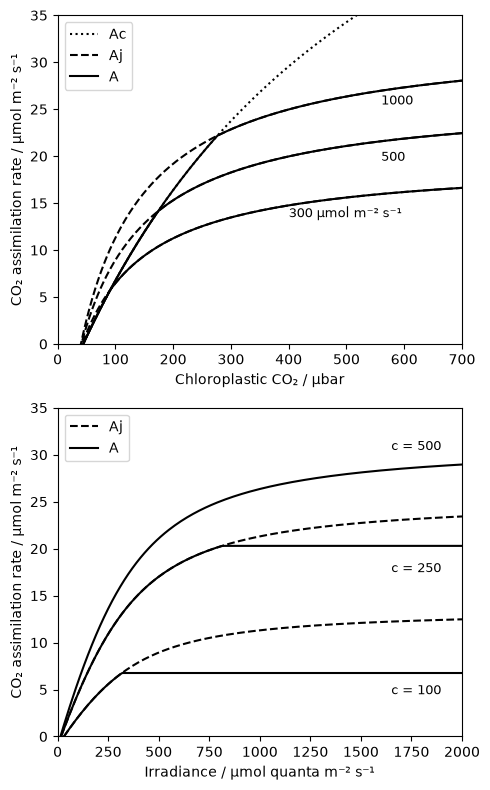

In [8]:
fig, axs = plt.subplots(nrows=2, ncols=1, figsize=(5, 8), squeeze=False)
ax0 = axs[0, 0]
ax0.text(560, 25.5, "1000", fontsize=9)
ax0.text(560, 19.5, "500", fontsize=9)
ax0.text(400, 13.5, "300 µmol m⁻² s⁻¹", fontsize=9)
ax0.plot(tables["ac"]["x"], tables["ac"]["Ac_inf"], color="black", ls=":", label="Ac")
ax0.plot(tables["i1000"]["x"], tables["i1000"]["Aj_inf"], color="black", ls="--", label="Aj")
ax0.plot(tables["i500"]["x"], tables["i500"]["Aj_inf"], color="black", ls="--")
ax0.plot(tables["i300"]["x"], tables["i300"]["Aj_inf"], color="black", ls="--")
ax0.plot(tables["i1000"]["x"], tables["i1000"]["A_inf"], color="black", ls="-", label="A")
ax0.plot(tables["i500"]["x"], tables["i500"]["A_inf"], color="black", ls="-")
ax0.plot(tables["i300"]["x"], tables["i300"]["A_inf"], color="black", ls="-")
ax0.set_xlabel("Chloroplastic CO₂ / µbar")
ax0.set_ylabel("CO₂ assimilation rate / µmol m⁻² s⁻¹")
ax0.set_xlim(0, 700)
ax0.set_ylim(0, 35)
ax0.legend()
ax1 = axs[1, 0]
ax1.text(1650, 30.5, "c = 500", fontsize=9)
ax1.text(1650, 17.5, "c = 250", fontsize=9)
ax1.text(1650, 4.5, "c = 100", fontsize=9)
ax1.plot(tables["c250"]["x"], tables["c250"]["Aj_inf"], color="black", ls="--", label="Aj")
ax1.plot(tables["c100"]["x"], tables["c100"]["Aj_inf"], color="black", ls="--")
ax1.plot(tables["c500"]["x"], tables["c500"]["A_inf"], color="black", ls="-", label="A")
ax1.plot(tables["c250"]["x"], tables["c250"]["A_inf"], color="black", ls="-")
ax1.plot(tables["c100"]["x"], tables["c100"]["A_inf"], color="black", ls="-")
ax1.set_xlabel("Irradiance / µmol quanta m⁻² s⁻¹")
ax1.set_ylabel("CO₂ assimilation rate / µmol m⁻² s⁻¹")
ax1.set_xlim(0, 2000)
ax1.set_ylim(0, 35)
ax1.legend()
plt.tight_layout()
plt.show()

## Figure 9.6: tobacco with mutant Rubiscos

In [9]:
tables = {}

# Scan wt
to_scan = pd.DataFrame({"Ci": np.linspace(0, 1800, 361), "Vcmax_25": 83.5, "Rd_25": 5.45})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Ac_inf"]].isna().any(axis=None)
tables["wt"] = {
    "x": np.linspace(0, 1800, 361),
    "Ac_inf": frame["Ac_inf"].to_numpy(),
}

# Scan l335
to_scan = pd.DataFrame({"Ci": np.linspace(0, 1800, 361), "Vcmax_25": 37, "Kc_25": 318, "Ko_25": 55.6, "gamma_star_25": 0.0007, "Rd_25": 2.5})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Ac_inf"]].isna().any(axis=None)
tables["l335"] = {
    "x": np.linspace(0, 1800, 361),
    "Ac_inf": frame["Ac_inf"].to_numpy(),
}

# Scan rubrum
to_scan = pd.DataFrame({"Ci": np.linspace(0, 1800, 361), "Vcmax_25": 42, "Kc_25": 4461, "Ko_25": 126, "gamma_star_25": 0.002075, "Rd_25": 1})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Ac_inf"]].isna().any(axis=None)
tables["rubrum"] = {
    "x": np.linspace(0, 1800, 361),
    "Ac_inf": frame["Ac_inf"].to_numpy(),
}

  0%|          | 0/361 [00:00<?, ?it/s]

100%|██████████| 361/361 [00:00<00:00, 3666.71it/s]

  0%|          | 0/361 [00:00<?, ?it/s]

100%|██████████| 361/361 [00:00<00:00, 3819.89it/s]

  0%|          | 0/361 [00:00<?, ?it/s]

100%|██████████| 361/361 [00:00<00:00, 3890.80it/s]

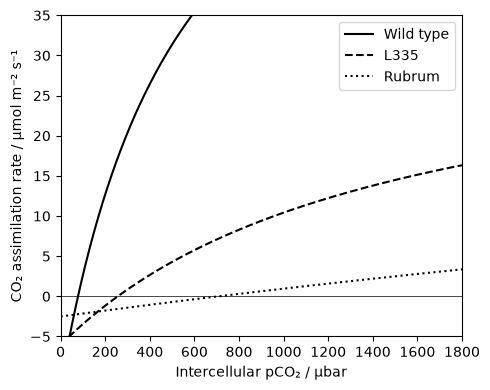

In [10]:
fig, axs = plt.subplots(nrows=1, ncols=1, figsize=(5, 4), squeeze=False)
ax0 = axs[0, 0]
ax0.plot(tables["wt"]["x"], tables["wt"]["Ac_inf"], color="black", ls="-", label="Wild type")
ax0.plot(tables["l335"]["x"], tables["l335"]["Ac_inf"], color="black", ls="--", label="L335")
ax0.plot(tables["rubrum"]["x"], tables["rubrum"]["Ac_inf"], color="black", ls=":", label="Rubrum")
ax0.set_xlabel("Intercellular pCO₂ / µbar")
ax0.set_ylabel("CO₂ assimilation rate / µmol m⁻² s⁻¹")
ax0.set_xlim(0, 1800)
ax0.set_ylim(-5, 35)
ax0.axhline(0, color="black", lw=0.5)
ax0.legend()
plt.tight_layout()
plt.show()

## Figure 9.7: supply and demand functions

In [11]:
tables = {}

# Scan demand
to_scan = pd.DataFrame({"Ci": np.linspace(0, 600, 241)})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_inf"]].isna().any(axis=None)
tables["demand"] = {
    "x": np.linspace(0, 600, 241),
    "A_inf": frame["A_inf"].to_numpy(),
}

# Scan supply
to_scan = pd.DataFrame({"Ci": np.array([273.237044994663,383])})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_supply"]].isna().any(axis=None)
tables["supply"] = {
    "x": np.array([273.237044994663,383]),
    "A_supply": frame["A_supply"].to_numpy(),
}

# Scan drop
to_scan = pd.DataFrame({"Ci": np.array([273.237044994663,273.237044994663]), "g": np.array([0,0.2])})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A_supply"]].isna().any(axis=None)
tables["drop"] = {
    "x": np.array([273.237044994663,273.237044994663]),
    "A_supply": frame["A_supply"].to_numpy(),
}

  0%|          | 0/241 [00:00<?, ?it/s]

100%|██████████| 241/241 [00:00<00:00, 3775.70it/s]

  0%|          | 0/2 [00:00<?, ?it/s]

100%|██████████| 2/2 [00:00<00:00, 2506.31it/s]

  0%|          | 0/2 [00:00<?, ?it/s]

100%|██████████| 2/2 [00:00<00:00, 2421.65it/s]

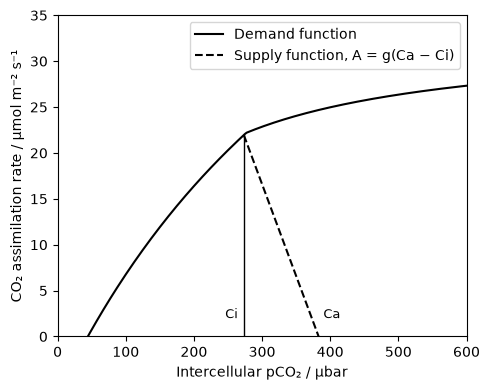

In [12]:
fig, axs = plt.subplots(nrows=1, ncols=1, figsize=(5, 4), squeeze=False)
ax0 = axs[0, 0]
ax0.text(265, 2, "Ci", fontsize=9, ha="right")
ax0.text(390, 2, "Ca", fontsize=9)
ax0.plot(tables["demand"]["x"], tables["demand"]["A_inf"], color="black", ls="-", label="Demand function")
ax0.plot(tables["supply"]["x"], tables["supply"]["A_supply"], color="black", ls="--", label="Supply function, A = g(Ca − Ci)")
ax0.plot(tables["drop"]["x"], tables["drop"]["A_supply"], color="black", ls="-", lw=1)
ax0.set_xlabel("Intercellular pCO₂ / µbar")
ax0.set_ylabel("CO₂ assimilation rate / µmol m⁻² s⁻¹")
ax0.set_xlim(0, 600)
ax0.set_ylim(0, 35)
ax0.legend()
plt.tight_layout()
plt.show()